# Electricity Demand Forecasting – Data Preparation

This notebook prepares the **Electricity Load Diagrams 2011–2014** dataset for four forecasting models:

- Artificial Neural Network (ANN)
- Long Short-Term Memory (LSTM)
- Transformer
- Tiny Time Mixers (TTM)

All four models use the same electricity series and test periods. Each model receives the previous **512 hours** and predicts the following **96 hours**.

**Dataset:** Trindade, A. (2015) *ElectricityLoadDiagrams20112014*. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C58C86

## 1. Setup

The first cell imports the required libraries and sets the main experiment values. The source file can be placed directly in `/content/` when using Google Colab.

In [ ]:
from pathlib import Path
import json
import warnings
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


SEED = 42
np.random.seed(SEED)

# File locations
PROJECT_DIR = Path("/content")
RAW_PATH = Path("/content/LD2011_2014 2.txt")

OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Forecast settings
CONTEXT_HOURS = 512
FORECAST_HOURS = 96
TRAIN_STRIDE = 1
EVALUATION_STRIDE = 96

# Client selection settings
BOUNDARY_DAYS = 7
MAX_ZERO_SHARE = 0.05

# Study period
STUDY_START = pd.Timestamp(
    "2012-01-01 00:00:00"
)

STUDY_END = pd.Timestamp(
    "2014-12-31 23:45:00"
)

# Chronological partitions
SPLITS = {
    "train": (
        pd.Timestamp("2012-01-01 00:00:00"),
        pd.Timestamp("2013-12-31 23:00:00"),
        TRAIN_STRIDE,
    ),
    "validation": (
        pd.Timestamp("2014-01-01 00:00:00"),
        pd.Timestamp("2014-06-30 23:00:00"),
        EVALUATION_STRIDE,
    ),
    "test": (
        pd.Timestamp("2014-07-01 00:00:00"),
        pd.Timestamp("2014-12-31 23:00:00"),
        EVALUATION_STRIDE,
    ),
}

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Dataset file was not found: {RAW_PATH}"
    )

print("Dataset file found.")
print(f"Source file: {RAW_PATH}")
print(
    f"File size: "
    f"{RAW_PATH.stat().st_size / (1024 ** 2):.2f} MB"
)
print(f"Output folder: {OUTPUT_DIR}")

Dataset file found.
Source file: /content/LD2011_2014 2.txt
File size: 678.06 MB
Output folder: /content/data/processed


## 2. Load the dataset

The file uses semicolons between columns and commas for decimal values. The timestamp is used as the index, and all client readings are converted to numbers.

In [ ]:
# Code block 2: Load and check the dataset

# Use the exact location of the uploaded dataset
RAW_PATH = Path("/content/LD2011_2014 2.txt")

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Dataset file was not found: {RAW_PATH}"
    )

# Remove any older dataset stored in memory
if "raw_data" in globals():
    del raw_data

# Load the dataset
raw_data = pd.read_csv(
    RAW_PATH,
    sep=";",
    decimal=",",
    index_col=0,
    low_memory=False,
)

# Convert the timestamp column into a datetime index
raw_data.index = pd.to_datetime(
    raw_data.index.astype(str).str.strip(),
    format="%Y-%m-%d %H:%M:%S",
    errors="raise",
)

raw_data.index.name = "timestamp"
raw_data = raw_data.sort_index()

# Convert all electricity readings to numbers
raw_data = raw_data.apply(
    pd.to_numeric,
    errors="coerce",
).astype("float32")

# Check the dataset dimensions
expected_shape = (140_256, 370)

print(f"File loaded: {RAW_PATH}")
print(
    f"File size: "
    f"{RAW_PATH.stat().st_size / (1024 ** 2):.2f} MB"
)
print(f"Dataset shape: {raw_data.shape}")
print(f"First timestamp: {raw_data.index.min()}")
print(f"Last timestamp: {raw_data.index.max()}")

missing_values = int(
    raw_data.isna().sum().sum()
)

negative_values = int(
    raw_data.lt(0).sum().sum()
)

duplicate_timestamps = int(
    raw_data.index.duplicated().sum()
)

print(f"Missing values: {missing_values:,}")
print(f"Negative values: {negative_values:,}")
print(
    f"Duplicate timestamps: "
    f"{duplicate_timestamps:,}"
)

if raw_data.shape != expected_shape:
    raise ValueError(
        f"Expected the dataset shape "
        f"{expected_shape}, but found "
        f"{raw_data.shape}."
    )

if missing_values > 0:
    raise ValueError(
        f"The dataset contains "
        f"{missing_values:,} missing values."
    )

if negative_values > 0:
    raise ValueError(
        f"The dataset contains "
        f"{negative_values:,} negative values."
    )

if duplicate_timestamps > 0:
    raise ValueError(
        f"The dataset contains "
        f"{duplicate_timestamps:,} duplicate timestamps."
    )

expected_start = pd.Timestamp(
    "2011-01-01 00:15:00"
)

expected_end = pd.Timestamp(
    "2015-01-01 00:00:00"
)

if raw_data.index.min() != expected_start:
    raise ValueError(
        f"Expected the first timestamp to be "
        f"{expected_start}, but found "
        f"{raw_data.index.min()}."
    )

if raw_data.index.max() != expected_end:
    raise ValueError(
        f"Expected the last timestamp to be "
        f"{expected_end}, but found "
        f"{raw_data.index.max()}."
    )

print("\nThe dataset was loaded successfully.")

File loaded: /content/LD2011_2014 2.txt
File size: 678.06 MB
Dataset shape: (140256, 370)
First timestamp: 2011-01-01 00:15:00
Last timestamp: 2015-01-01 00:00:00
Missing values: 0
Negative values: 0
Duplicate timestamps: 0

The dataset was loaded successfully.


## 3. Handle daylight-saving-time changes

The Portuguese clock changes create unusual readings in March and October. The missing spring hour is filled using nearby values. The repeated autumn hour is divided by two. The changes are saved in a separate file.

Other zero readings are kept because the dataset does not show whether they are real zero usage or missing meter readings.

In [ ]:
print("FILE INFORMATION")
print("RAW_PATH:", RAW_PATH)
print("File exists:", RAW_PATH.exists())
print("File size:", RAW_PATH.stat().st_size, "bytes")

print("\nRAW DATA INFORMATION")
print("Shape:", raw_data.shape)
print("Index type:", type(raw_data.index))
print("Index data type:", raw_data.index.dtype)
print("Number of columns:", raw_data.shape[1])
print("First timestamp:", raw_data.index.min())
print("Last timestamp:", raw_data.index.max())
print("Duplicate timestamps:", raw_data.index.duplicated().sum())

print("\nFIRST 10 TIMESTAMPS")
print(raw_data.index[:10].tolist())

print("\nLAST 10 TIMESTAMPS")
print(raw_data.index[-10:].tolist())

print("\nTIMESTAMP INTERVALS")
time_differences = (
    pd.Series(raw_data.index)
    .sort_values()
    .diff()
    .value_counts()
    .head(10)
)

print(time_differences)

print("\nFIRST THREE LINES OF THE ORIGINAL FILE")

with open(
    RAW_PATH,
    "r",
    encoding="utf-8-sig",
    errors="replace",
) as file:
    for _ in range(3):
        print(repr(file.readline()))

FILE INFORMATION
RAW_PATH: /content/LD2011_2014 2.txt
File exists: True
File size: 710998915 bytes

RAW DATA INFORMATION
Shape: (140256, 370)
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index data type: datetime64[ns]
Number of columns: 370
First timestamp: 2011-01-01 00:15:00
Last timestamp: 2015-01-01 00:00:00
Duplicate timestamps: 0

FIRST 10 TIMESTAMPS
[Timestamp('2011-01-01 00:15:00'), Timestamp('2011-01-01 00:30:00'), Timestamp('2011-01-01 00:45:00'), Timestamp('2011-01-01 01:00:00'), Timestamp('2011-01-01 01:15:00'), Timestamp('2011-01-01 01:30:00'), Timestamp('2011-01-01 01:45:00'), Timestamp('2011-01-01 02:00:00'), Timestamp('2011-01-01 02:15:00'), Timestamp('2011-01-01 02:30:00')]

LAST 10 TIMESTAMPS
[Timestamp('2014-12-31 21:45:00'), Timestamp('2014-12-31 22:00:00'), Timestamp('2014-12-31 22:15:00'), Timestamp('2014-12-31 22:30:00'), Timestamp('2014-12-31 22:45:00'), Timestamp('2014-12-31 23:00:00'), Timestamp('2014-12-31 23:15:00'), Timestamp('2014-12-

## 4. Create the Study Period

The original dataset covers electricity readings from 2011 to 2014. This project uses the continuous period from January 2012 to December 2014 because several clients were not active during the earlier part of the dataset.

The original timestamps show the end of each 15-minute period. Therefore, the timestamps are shifted back by 15 minutes so that they show the beginning of each period.

This section creates the 2012–2014 study dataset and checks that:

- the timeline follows continuous 15-minute intervals;
- the expected number of clients is available;
- no timestamps are missing;
- and no electricity readings are missing.

In [ ]:
# Confirm that the dataset has already been loaded
if "raw_data" not in globals():
    raise NameError(
        "raw_data does not exist. Run code block 2 first."
    )

# Confirm the original UCI dataset dimensions
expected_shape = (140_256, 370)

if raw_data.shape != expected_shape:
    raise ValueError(
        f"Expected {expected_shape}, but found "
        f"{raw_data.shape}. Check the dataset file."
    )

# Recreate the official timestamp sequence
raw_data.index = pd.date_range(
    start="2011-01-01 00:15:00",
    end="2015-01-01 00:00:00",
    freq="15min",
    name="timestamp",
)

# Convert interval-end timestamps to interval-start timestamps
cleaned_data = raw_data.copy()

cleaned_data.index = (
    cleaned_data.index
    - pd.Timedelta(minutes=15)
)

# Define the study period
STUDY_START = pd.Timestamp(
    "2012-01-01 00:00:00"
)

STUDY_END = pd.Timestamp(
    "2014-12-31 23:45:00"
)

# Select the 2012–2014 study period
study_15m = cleaned_data.loc[
    STUDY_START:STUDY_END
].copy()

# Validate the result
expected_timestamps = pd.date_range(
    start=STUDY_START,
    end=STUDY_END,
    freq="15min",
    name="timestamp",
)

if not study_15m.index.equals(
    expected_timestamps
):
    raise ValueError(
        "The study timeline was not created correctly."
    )

missing_values = int(
    study_15m.isna().sum().sum()
)

if missing_values > 0:
    raise ValueError(
        f"The study data contains "
        f"{missing_values:,} missing values."
    )

print("study_15m was created successfully.")
print(f"Shape: {study_15m.shape}")
print(
    f"Period: {study_15m.index.min()} "
    f"to {study_15m.index.max()}"
)
print(f"Missing values: {missing_values:,}")

study_15m was created successfully.
Shape: (105216, 370)
Period: 2012-01-01 00:00:00 to 2014-12-31 23:45:00
Missing values: 0


## 5. Select Valid Electricity Clients

Some clients started using electricity after the dataset collection had already begun. Their earlier readings therefore contain long periods of zero values. Including these clients could create an incorrect increase in the total electricity demand.

A client is selected when:

- it has electricity readings near the beginning and end of the study period;
- it contains no missing values;
- it contains no negative values; and
- its zero readings are not more than 5% of the study period.

Short periods of zero consumption are kept because they may represent genuine low or zero electricity usage. The selected clients are used to create the final aggregated electricity-demand series.

In [ ]:
# Code block 5: Select valid electricity clients

if "study_15m" not in globals():
    raise NameError(
        "study_15m does not exist. "
        "Run the previous block first."
    )

if study_15m.empty:
    raise ValueError(
        "study_15m is empty."
    )

study_missing_values = int(
    study_15m.isna().sum().sum()
)

if study_missing_values > 0:
    raise ValueError(
        f"study_15m contains "
        f"{study_missing_values:,} missing values."
    )


def longest_zero_run(series):
    """Find the longest continuous sequence of zeros."""

    zero_mask = series.eq(0).to_numpy(
        dtype=np.int8
    )

    if not zero_mask.any():
        return 0

    changes = np.diff(
        np.r_[0, zero_mask, 0]
    )

    starts = np.flatnonzero(
        changes == 1
    )

    ends = np.flatnonzero(
        changes == -1
    )

    return int(
        (ends - starts).max()
    )


def create_client_metadata(data):
    """Check each client against the selection rules."""

    first_period_end = (
        STUDY_START
        + pd.Timedelta(days=BOUNDARY_DAYS)
        - pd.Timedelta(minutes=15)
    )

    last_period_start = (
        STUDY_END
        - pd.Timedelta(days=BOUNDARY_DAYS)
        + pd.Timedelta(minutes=15)
    )

    first_period = data.loc[
        STUDY_START:first_period_end
    ]

    last_period = data.loc[
        last_period_start:STUDY_END
    ]

    details = pd.DataFrame(
        index=data.columns
    )

    details.index.name = "client_id"

    details["active_at_start"] = (
        first_period.ne(0).any()
    )

    details["active_at_end"] = (
        last_period.ne(0).any()
    )

    details["missing_count"] = (
        data.isna().sum()
    )

    details["negative_count"] = (
        data.lt(0).sum()
    )

    details["zero_share"] = (
        data.eq(0).mean()
    )

    details["longest_zero_run"] = [
        longest_zero_run(data[client])
        for client in data.columns
    ]

    details["selected"] = (
        details["active_at_start"]
        & details["active_at_end"]
        & details["missing_count"].eq(0)
        & details["negative_count"].eq(0)
        & details["zero_share"].le(
            MAX_ZERO_SHARE
        )
    )

    return details


client_metadata = create_client_metadata(
    study_15m
)

selected_clients = client_metadata.index[
    client_metadata["selected"]
].tolist()


selection_summary = pd.Series({
    "Total clients": len(client_metadata),

    "Active at the beginning": int(
        client_metadata[
            "active_at_start"
        ].sum()
    ),

    "Active at the end": int(
        client_metadata[
            "active_at_end"
        ].sum()
    ),

    "No missing values": int(
        client_metadata[
            "missing_count"
        ].eq(0).sum()
    ),

    "No negative values": int(
        client_metadata[
            "negative_count"
        ].eq(0).sum()
    ),

    "Zero share at or below 5%": int(
        client_metadata[
            "zero_share"
        ].le(MAX_ZERO_SHARE).sum()
    ),

    "Passed every rule": len(
        selected_clients
    ),
})

display(
    selection_summary.to_frame(
        name="number_of_clients"
    )
)


if len(selected_clients) == 0:
    raise ValueError(
        "No clients passed every selection rule. "
        "Check the summary above."
    )


client_metadata.reset_index().to_csv(
    OUTPUT_DIR / "client_metadata.csv",
    index=False,
)

pd.Series(
    selected_clients,
    name="client_id",
).to_csv(
    OUTPUT_DIR / "selected_clients.csv",
    index=False,
)


print(
    f"Selected clients: "
    f"{len(selected_clients)}"
)

print(
    f"Removed clients: "
    f"{len(client_metadata) - len(selected_clients)}"
)

,number_of_clients
Total clients,370
Active at the beginning,321
Active at the end,368
No missing values,370
No negative values,370
Zero share at or below 5%,313
Passed every rule,313


Selected clients: 313
Removed clients: 57


## 6. Create the hourly electricity series

The source data contains one power reading every 15 minutes. Four readings are changed into hourly energy using:

\[
E_h = \frac{x_1+x_2+x_3+x_4}{4}
\]

The hourly values of the selected clients are then added together to create one electricity-demand series.

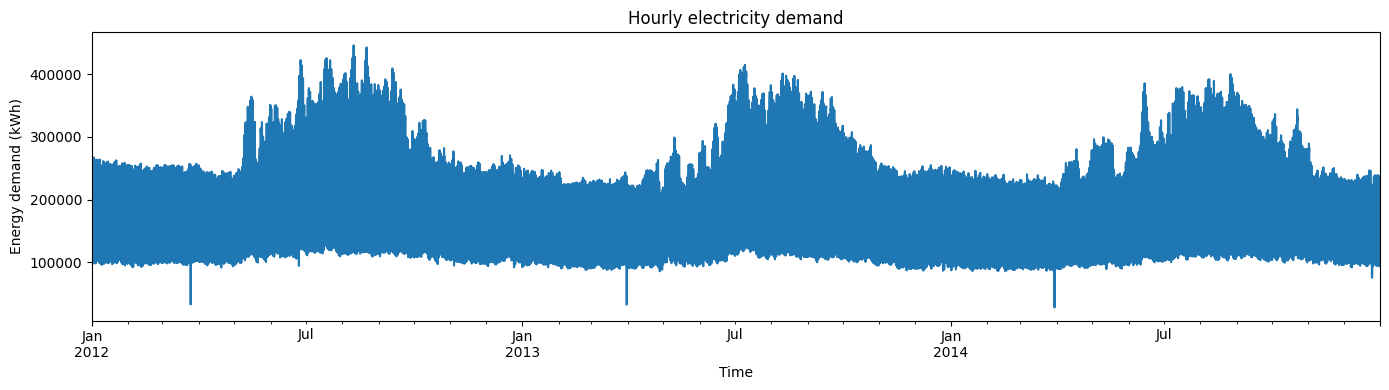

Selected clients: 313
Hourly observations: 26,304
Period: 2012-01-01 00:00:00 to 2014-12-31 23:00:00


,total_load_kwh
count,26304.000000
mean,203225.640625
std,79698.632812
min,28046.318359
25%,126859.294922
50%,210220.382812
75%,249477.582031
max,445878.781250


In [ ]:
# Code block 6: Create the hourly electricity series

required_variables = [
    "study_15m",
    "client_metadata",
    "selected_clients",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables do not exist: "
        f"{missing_variables}. Run code blocks 3 and 4 first."
    )

if len(selected_clients) == 0:
    raise ValueError(
        "The selected-client list is empty. "
        "Run code block 4 and check its selection summary."
    )


def create_hourly_series(data, clients):
    """Convert 15-minute power readings into hourly energy."""

    selected_data = data.loc[:, clients].copy()

    # Each kW reading covers one quarter of an hour.
    hourly_by_client = (
        (selected_data / 4)
        .resample("1h")
        .sum(min_count=4)
        .astype("float32")
    )

    hourly_total = (
        hourly_by_client
        .sum(axis=1)
        .astype("float32")
    )

    hourly_total.name = "total_load_kwh"

    return hourly_by_client, hourly_total


hourly_clients, hourly_demand = (
    create_hourly_series(
        study_15m,
        selected_clients,
    )
)

expected_hours = pd.date_range(
    start="2012-01-01 00:00:00",
    end="2014-12-31 23:00:00",
    freq="1h",
    name="timestamp",
)

if not hourly_demand.index.equals(
    expected_hours
):
    missing_hours = expected_hours.difference(
        hourly_demand.index
    )

    raise ValueError(
        f"The hourly timeline is incomplete. "
        f"Missing hours: {len(missing_hours):,}."
    )

missing_hourly_values = int(
    hourly_clients.isna().sum().sum()
)

negative_hourly_values = int(
    hourly_clients.lt(0).sum().sum()
)

if missing_hourly_values > 0:
    raise ValueError(
        f"The hourly client data contains "
        f"{missing_hourly_values:,} missing values."
    )

if negative_hourly_values > 0:
    raise ValueError(
        f"The hourly client data contains "
        f"{negative_hourly_values:,} negative values."
    )

hourly_clients.to_parquet(
    OUTPUT_DIR / "hourly_clients.parquet"
)

hourly_demand.to_frame().to_csv(
    OUTPUT_DIR / "hourly_demand.csv"
)

hourly_demand.plot(
    figsize=(14, 4),
    title="Hourly electricity demand",
    ylabel="Energy demand (kWh)",
)

plt.xlabel("Time")
plt.tight_layout()
plt.show()

print(f"Selected clients: {len(selected_clients)}")
print(f"Hourly observations: {len(hourly_demand):,}")
print(
    f"Period: {hourly_demand.index.min()} "
    f"to {hourly_demand.index.max()}"
)

display(
    hourly_demand.describe().to_frame()
)

## 7. Split and scale the data

The data is divided in date order:

- **Training:** January 2012 to December 2013
- **Validation:** January 2014 to June 2014
- **Testing:** July 2014 to December 2014

The mean and standard deviation are calculated from the training data only. This prevents information from the validation and test periods from entering the training process.

In [ ]:
def add_partitions(series):
    frame = series.to_frame()
    frame["partition"] = ""

    for name, (start, end, _) in SPLITS.items():
        frame.loc[start:end, "partition"] = name

    if frame["partition"].eq("").any():
        raise ValueError("Some timestamps were not assigned to a partition.")

    return frame


def scale_using_training_data(frame):
    train_start, train_end, _ = SPLITS["train"]
    training_values = frame.loc[train_start:train_end, "total_load_kwh"]

    mean = float(training_values.mean())
    standard_deviation = float(training_values.std(ddof=0))

    if standard_deviation == 0:
        raise ValueError("The training standard deviation is zero.")

    frame = frame.copy()
    frame["total_load_scaled"] = (
        (frame["total_load_kwh"] - mean) / standard_deviation
    ).astype("float32")

    return frame, mean, standard_deviation


system_data = add_partitions(hourly_demand)
system_data, train_mean, train_std = scale_using_training_data(system_data)

scaler_details = {
    "method": "standard scaling",
    "mean": train_mean,
    "standard_deviation": train_std,
    "fitted_on": "training data only",
}

(OUTPUT_DIR / "scaler.json").write_text(
    json.dumps(scaler_details, indent=2)
)
system_data.to_csv(OUTPUT_DIR / "system_load_hourly.csv")
system_data.to_parquet(OUTPUT_DIR / "system_load_hourly.parquet")

display(system_data["partition"].value_counts().rename("hours"))
print(scaler_details)

,hours
partition,
train,17544
test,4416
validation,4344


{'method': 'standard scaling', 'mean': 205781.5625, 'standard_deviation': 80850.5234375, 'fitted_on': 'training data only'}


## 8. Create forecasting windows

Each sample contains:

- 512 hours of past electricity demand;
- 96 hours of future electricity demand.

Training windows move forward by one hour. Validation and test windows move forward by 96 hours, so their target periods do not overlap. A previous-week forecast is also saved as a simple baseline.

In [ ]:
# Section 8: Create forecasting windows and save them as CSV

def make_windows(
    frame,
    partition_name,
    start_time,
    end_time,
    stride,
):
    """Create input, target and baseline forecasting windows."""

    timestamps = frame.index

    raw_values = frame[
        "total_load_kwh"
    ].to_numpy(dtype=np.float32)

    scaled_values = frame[
        "total_load_scaled"
    ].to_numpy(dtype=np.float32)

    partition_start = timestamps.get_loc(
        start_time
    )

    partition_end = timestamps.get_loc(
        end_time
    )

    first_target = max(
        partition_start,
        CONTEXT_HOURS,
    )

    last_target = (
        partition_end
        - FORECAST_HOURS
        + 1
    )

    target_positions = np.arange(
        first_target,
        last_target + 1,
        stride,
        dtype=np.int64,
    )

    if len(target_positions) == 0:
        raise ValueError(
            f"No windows were created for "
            f"{partition_name}."
        )

    x_raw = np.stack([
        raw_values[
            position - CONTEXT_HOURS:
            position
        ]
        for position in target_positions
    ])

    y_raw = np.stack([
        raw_values[
            position:
            position + FORECAST_HOURS
        ]
        for position in target_positions
    ])

    x_scaled = np.stack([
        scaled_values[
            position - CONTEXT_HOURS:
            position
        ]
        for position in target_positions
    ])

    y_scaled = np.stack([
        scaled_values[
            position:
            position + FORECAST_HOURS
        ]
        for position in target_positions
    ])

    # Previous-week demand baseline
    seasonal_naive = np.stack([
        raw_values[
            position - 168:
            position - 168 + FORECAST_HOURS
        ]
        for position in target_positions
    ])

    metadata = pd.DataFrame({
        "partition": partition_name,
        "window_number": np.arange(
            len(target_positions)
        ),
        "input_start": timestamps[
            target_positions - CONTEXT_HOURS
        ],
        "input_end": timestamps[
            target_positions - 1
        ],
        "target_start": timestamps[
            target_positions
        ],
        "target_end": timestamps[
            target_positions
            + FORECAST_HOURS
            - 1
        ],
        "target_position": target_positions,
    })

    return {
        "x_raw": x_raw,
        "y_raw": y_raw,
        "x_scaled": x_scaled,
        "y_scaled": y_scaled,
        "seasonal_naive": seasonal_naive,
        "metadata": metadata,
    }


def save_matrix_as_csv(
    matrix,
    file_path,
    column_prefix,
):
    """Save a two-dimensional array as a CSV file."""

    columns = [
        f"{column_prefix}_{number + 1:03d}"
        for number in range(
            matrix.shape[1]
        )
    ]

    pd.DataFrame(
        matrix,
        columns=columns,
    ).to_csv(
        file_path,
        index=False,
        float_format="%.8f",
    )


# Remove NPZ files created by an earlier run
for npz_file in OUTPUT_DIR.glob(
    "*_windows.npz"
):
    npz_file.unlink()

window_metadata_tables = []

for partition_name, (
    start_time,
    end_time,
    stride,
) in SPLITS.items():

    print(
        f"Creating {partition_name} windows..."
    )

    partition_data = make_windows(
        frame=system_data,
        partition_name=partition_name,
        start_time=start_time,
        end_time=end_time,
        stride=stride,
    )

    partition_folder = (
        OUTPUT_DIR / partition_name
    )

    # Remove old CSV files from this partition
    if partition_folder.exists():
        shutil.rmtree(
            partition_folder
        )

    partition_folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    save_matrix_as_csv(
        partition_data["x_raw"],
        partition_folder / "x_raw.csv",
        "input_hour",
    )

    save_matrix_as_csv(
        partition_data["y_raw"],
        partition_folder / "y_raw.csv",
        "target_hour",
    )

    save_matrix_as_csv(
        partition_data["x_scaled"],
        partition_folder
        / "x_scaled.csv",
        "input_hour",
    )

    save_matrix_as_csv(
        partition_data["y_scaled"],
        partition_folder
        / "y_scaled.csv",
        "target_hour",
    )

    save_matrix_as_csv(
        partition_data[
            "seasonal_naive"
        ],
        partition_folder
        / "seasonal_naive.csv",
        "forecast_hour",
    )

    partition_data[
        "metadata"
    ].to_csv(
        partition_folder
        / "window_metadata.csv",
        index=False,
    )

    window_metadata_tables.append(
        partition_data["metadata"]
    )

    print(
        f"{partition_name.capitalize()}: "
        f"{partition_data['x_raw'].shape[0]} "
        f"windows"
    )

    print(
        f"Input shape: "
        f"{partition_data['x_raw'].shape}"
    )

    print(
        f"Target shape: "
        f"{partition_data['y_raw'].shape}"
    )

    # Release the arrays before creating the next partition
    del partition_data


# Save one combined metadata file
window_metadata = pd.concat(
    window_metadata_tables,
    ignore_index=True,
)

window_metadata.to_csv(
    OUTPUT_DIR / "window_metadata.csv",
    index=False,
)

display(
    window_metadata.groupby(
        "partition"
    ).agg(
        windows=(
            "window_number",
            "count",
        ),
        first_target=(
            "target_start",
            "min",
        ),
        last_target=(
            "target_end",
            "max",
        ),
    )
)

print(
    "\nAll forecasting windows "
    "were saved as CSV files."
)

Creating train windows...
Train: 16937 windows
Input shape: (16937, 512)
Target shape: (16937, 96)
Creating validation windows...
Validation: 45 windows
Input shape: (45, 512)
Target shape: (45, 96)
Creating test windows...
Test: 46 windows
Input shape: (46, 512)
Target shape: (46, 96)


,windows,first_target,last_target
partition,,,
test,46,2014-07-01 00:00:00,2014-12-31 23:00:00
train,16937,2012-01-22 08:00:00,2013-12-31 23:00:00
validation,45,2014-01-01 00:00:00,2014-06-29 23:00:00



All forecasting windows were saved as CSV files.


## 9. Inputs for the four models

The data does not need to be prepared four separate times. The same saved windows are reshaped for each model.

| Model | Data | Shape |
|---|---|---|
| ANN | Scaled values | `(samples, 512)` |
| LSTM | Scaled values | `(samples, 512, 1)` |
| Transformer | Scaled values | `(samples, 512, 1)` |
| TTM | Original values | `(samples, 512, 1)` |

TTM uses the original values because its own model code may apply internal scaling. All final predictions must be converted to kWh before evaluation.

In [ ]:
# Section 9: Load the saved CSV data for a model

def read_csv_matrix(file_path):
    """Load a CSV matrix as float32."""

    return pd.read_csv(
        file_path
    ).to_numpy(
        dtype=np.float32
    )


def load_model_data(
    partition,
    model_name,
):
    """Load one partition for the selected model."""

    partition_folder = (
        OUTPUT_DIR / partition
    )

    model_name = model_name.lower()

    if model_name not in {
        "ann",
        "lstm",
        "transformer",
        "ttm",
    }:
        raise ValueError(
            "model_name must be ann, lstm, "
            "transformer or ttm."
        )

    if model_name == "ttm":
        x_values = read_csv_matrix(
            partition_folder
            / "x_raw.csv"
        )

        y_training = read_csv_matrix(
            partition_folder
            / "y_raw.csv"
        )

    else:
        x_values = read_csv_matrix(
            partition_folder
            / "x_scaled.csv"
        )

        y_training = read_csv_matrix(
            partition_folder
            / "y_scaled.csv"
        )

    # Add one feature dimension for sequence models
    if model_name in {
        "lstm",
        "transformer",
        "ttm",
    }:
        x_values = x_values[
            ...,
            np.newaxis,
        ]

    y_original = read_csv_matrix(
        partition_folder
        / "y_raw.csv"
    )

    baseline = read_csv_matrix(
        partition_folder
        / "seasonal_naive.csv"
    )

    metadata = pd.read_csv(
        partition_folder
        / "window_metadata.csv",
        parse_dates=[
            "input_start",
            "input_end",
            "target_start",
            "target_end",
        ],
    )

    return {
        "x": x_values,
        "y_training": y_training,
        "y_original": y_original,
        "seasonal_naive": baseline,
        "metadata": metadata,
    }


# Example: check the training input shape for each model
for model_name in [
    "ann",
    "lstm",
    "transformer",
    "ttm",
]:
    example_data = load_model_data(
        partition="train",
        model_name=model_name,
    )

    print(
        f"{model_name.upper():11s} "
        f"input shape: "
        f"{example_data['x'].shape}"
    )

    del example_data

ANN         input shape: (16937, 512)
LSTM        input shape: (16937, 512, 1)
TRANSFORMER input shape: (16937, 512, 1)
TTM         input shape: (16937, 512, 1)


## 10. Final checks

The last cell checks the saved data and records the main settings used in this notebook. MAE and RMSE can be used as the main evaluation measures. MAPE should be used carefully when an actual demand value is zero.

In [ ]:
# Section 10: Check the processed CSV files

def count_csv_rows(file_path):
    """Count data rows without loading the complete CSV."""

    with open(
        file_path,
        "r",
        encoding="utf-8",
    ) as file:
        return sum(
            1 for _ in file
        ) - 1


def count_csv_columns(file_path):
    """Count columns using the CSV header."""

    return len(
        pd.read_csv(
            file_path,
            nrows=0,
        ).columns
    )


def check_processed_outputs():
    """Check the final hourly data and CSV windows."""

    expected_partition_hours = {
        "train": 17_544,
        "validation": 4_344,
        "test": 4_416,
    }

    expected_window_counts = {
        "train": 16_937,
        "validation": 45,
        "test": 46,
    }

    if len(system_data) != 26_304:
        raise ValueError(
            "The hourly dataset should contain "
            "26,304 rows."
        )

    if system_data[
        "total_load_kwh"
    ].isna().any():
        raise ValueError(
            "The final demand series contains "
            "missing values."
        )

    if system_data[
        "total_load_kwh"
    ].lt(0).any():
        raise ValueError(
            "The final demand series contains "
            "negative values."
        )

    actual_partition_hours = (
        system_data[
            "partition"
        ].value_counts().to_dict()
    )

    if (
        actual_partition_hours
        != expected_partition_hours
    ):
        raise ValueError(
            "Unexpected partition sizes: "
            f"{actual_partition_hours}"
        )

    required_files = [
        "x_raw.csv",
        "y_raw.csv",
        "x_scaled.csv",
        "y_scaled.csv",
        "seasonal_naive.csv",
        "window_metadata.csv",
    ]

    for partition_name in SPLITS:
        partition_folder = (
            OUTPUT_DIR
            / partition_name
        )

        for file_name in required_files:
            file_path = (
                partition_folder
                / file_name
            )

            if not file_path.exists():
                raise FileNotFoundError(
                    f"Missing file: {file_path}"
                )

        actual_windows = count_csv_rows(
            partition_folder
            / "x_raw.csv"
        )

        expected_windows = (
            expected_window_counts[
                partition_name
            ]
        )

        if actual_windows != expected_windows:
            raise ValueError(
                f"{partition_name} should contain "
                f"{expected_windows} windows, but "
                f"contains {actual_windows}."
            )

        input_columns = count_csv_columns(
            partition_folder
            / "x_raw.csv"
        )

        target_columns = count_csv_columns(
            partition_folder
            / "y_raw.csv"
        )

        if input_columns != CONTEXT_HOURS:
            raise ValueError(
                f"{partition_name} input files "
                f"should contain "
                f"{CONTEXT_HOURS} columns."
            )

        if target_columns != FORECAST_HOURS:
            raise ValueError(
                f"{partition_name} target files "
                f"should contain "
                f"{FORECAST_HOURS} columns."
            )

        print(
            f"{partition_name.capitalize()}: "
            f"{actual_windows} windows passed."
        )


check_processed_outputs()


experiment_details = {
    "random_seed": SEED,

    "study_period": [
        str(STUDY_START),
        str(STUDY_END),
    ],

    "selected_clients": len(
        selected_clients
    ),

    "maximum_zero_share":
        MAX_ZERO_SHARE,

    "context_hours":
        CONTEXT_HOURS,

    "forecast_hours":
        FORECAST_HOURS,

    "training_stride":
        TRAIN_STRIDE,

    "evaluation_stride":
        EVALUATION_STRIDE,

    "saved_format": "CSV",

    "main_metrics": [
        "MAE",
        "RMSE",
    ],

    "additional_metric":
        "MAPE with zero-value handling",
}

(
    OUTPUT_DIR
    / "experiment_details.json"
).write_text(
    json.dumps(
        experiment_details,
        indent=2,
    )
)

print("\nAll final checks passed.")

Train: 16937 windows passed.
Validation: 45 windows passed.
Test: 46 windows passed.

All final checks passed.


## 11. Download the Processed Dataset

The complete processed folder is compressed into one ZIP file. It contains the training, validation and test CSV files together with the scaling values, client information, experiment settings and window timestamps.

In [ ]:
# Section 11: Create and download the final ZIP file

from google.colab import files


ZIP_BASE = Path(
    "/content/electricity_processed_data"
)

ZIP_PATH = Path(
    f"{ZIP_BASE}.zip"
)

# Remove an older ZIP file
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

created_zip = shutil.make_archive(
    base_name=str(ZIP_BASE),
    format="zip",
    root_dir=str(OUTPUT_DIR),
)

zip_size_mb = (
    Path(created_zip).stat().st_size
    / (1024 ** 2)
)

print("Processed folder compressed successfully.")
print(f"ZIP file: {created_zip}")
print(f"ZIP size: {zip_size_mb:.2f} MB")

files.download(created_zip)

Processed folder compressed successfully.
ZIP file: /content/electricity_processed_data.zip
ZIP size: 18.24 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>